In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pickle

import sys
sys.path.append('../../../')

# Import methods
from QGP.Soliton_Gen import *
from Utilities import *

import config
i = 1j

In [10]:
2**18

262144

# Bright solitons

## Static

In [2]:
path_bright = "../../../Heaven_scripts/Results/Errors/Bright/"
path_bright_space = "../../../Heaven_scripts/Results/Errors/Bright/space_order_2/"

In [4]:
theo = pickle.load(open(path_bright + "theo_bright_w_0.71_k_0.25_L_40.pck", "rb"))
c = np.sqrt(2)/2
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [5]:
order = 2
tf = 5
k = 1/4
L = 40

Ns = np.array([2**(j) for j in range(4, 18)])
Nts = np.array([20, 50, 100, 200, 500, 2000, 5000])
dts = tf/Nts

base = "errors_Nt_"
folders = []
errors = []
for Nt in Nts:
    folder_name = path_bright_space + base + "{N}_order_{o}/".format(N=Nt, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

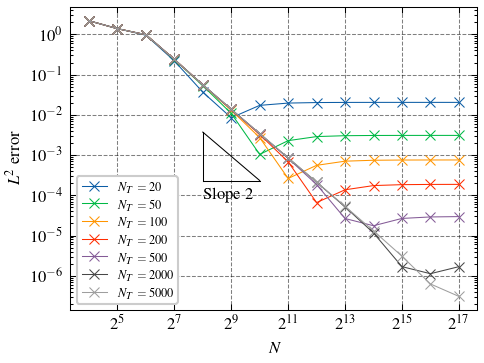

In [6]:
hs = 2*L/Ns

for j in range(len(Nts)):
    Nt = Nts[j]
    plt.plot(Ns, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = {}$".format(Nt))

# Order lines
N_plot_2 = Ns[4:7]

s_2 = 2
order_2 = 1/N_plot_2**(s_2)*np.exp(5.5)

plt.plot(N_plot_2, order_2, color="black", lw=.5, ls="-")
plt.plot(N_plot_2, np.tile(order_2[-1], len(N_plot_2)), color="black", lw=.5, ls="-")
plt.plot(np.tile(N_plot_2[0], len(order_2)), order_2, color="black", lw=.5, ls="-")
plt.text(N_plot_2[0], order_2[-1]-1.5e-4, r'Slope 2')

plt.legend(fontsize=6)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N$")
plt.ylabel(r"$L^2$ error")#r"$||\psi_{num} - \psi_{theo}||_{L^2}$")
plt.savefig("Img/Errors_Heaven/Bright/Static/Bright_N_L_40_c_0.71_k_0.25.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Bright/Static/Bright_N_L_40_c_0.71_k_0.25.pgf", dpi=300, bbox_inches = "tight")
#plt.grid()
plt.show()

In [7]:
EOCs = []

dic_EOC = {}
for n in range(len(Nts)):
    EOC = []
    for j in range(len(Ns)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N_T={}$".format(Nts[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Ns)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Bright/Static/EOC_tab_bright_N_L_40_c_0.71_k_0.25.txt")

       $N_T=20$  $N_T=50$  $N_T=100$  $N_T=200$  $N_T=500$  $N_T=2000$  \
16       0.6452    0.6532     0.6543     0.6546     0.6546      0.6546   
32       0.5475    0.5034     0.4976     0.4962     0.4958      0.4957   
64       2.1220    2.0428     2.0327     2.0302     2.0296      2.0294   
128      2.5812    2.1621     2.1166     2.1058     2.1029      2.1023   
256      2.1144    2.2907     2.0850     2.0405     2.0285      2.0264   
512     -1.0238    3.3836     2.2668     2.0661     2.0169      2.0084   
1024    -0.1884   -1.1355     3.3692     2.2589     2.0393      2.0049   
2048    -0.0438   -0.3351    -1.0834     3.3615     2.1566      2.0100   
4096    -0.0108   -0.0741    -0.3430    -1.0556     2.8059      2.0370   
8192    -0.0027   -0.0180    -0.0757    -0.3470     0.5985      2.1549   
16384   -0.0007   -0.0045    -0.0184    -0.0765    -0.6041      2.7821   
32768   -0.0002   -0.0011    -0.0046    -0.0186    -0.1230      0.5824   
65536   -0.0000   -0.0003    -0.0011  

## Moving

In [2]:
path_bright = "../../../Heaven_scripts/Results/Errors/Bright/"
path_bright_space = "../../../Heaven_scripts/Results/Errors/Bright/moving_space_order_2/"

In [3]:
theo = pickle.load(open(path_bright + "theo_bright_c_0.71_k_0.25_w_1_L_100.pck", "rb"))
c = np.sqrt(2)/2
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [4]:
order = 2
tf = 5
k = 1/4
L = 100

Ns = np.array([2**(j) for j in range(4, 18)])
Nts = np.array([20, 50, 100, 200, 500, 2000, 5000])
dts = tf/Nts

base = "errors_Nt_"
folders = []
errors = []
for Nt in Nts:
    folder_name = path_bright_space + base + "{N}_order_{o}/".format(N=Nt, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

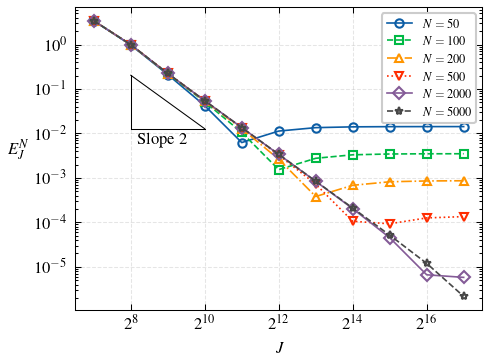

In [5]:
hs = 2*L/Ns

for j in range(1, len(Nts)):
    Nt = Nts[j]
    plt.plot(Ns[3:], errors[j][3:], lw=.8, markeredgewidth=1, 
             label=r"$N = {}$".format(Nt), markerfacecolor='none')

# Order lines
N_plot_2 = Ns[4:7]

s_2 = 2
order_2 = 1/N_plot_2**(s_2)*np.exp(9.5)

plt.plot(N_plot_2, order_2, color="black", lw=.5, ls="-", marker="none")
plt.plot(N_plot_2, np.tile(order_2[-1], len(N_plot_2)), color="black", lw=.5, ls="-", marker="none")
plt.plot(np.tile(N_plot_2[0], len(order_2)), order_2, color="black", lw=.5, ls="-", marker="none")
plt.text(N_plot_2[0]+2**5, order_2[-1]-7e-3, r'Slope 2')

plt.legend(fontsize=6)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$J$")
plt.ylabel(r"$E^N_J$", rotation='horizontal', ha='right')#r"$||\psi_{num} - \psi_{theo}||_{L^2}$")
plt.savefig("Img/Errors_Heaven/Bright/Moving/pdf/Bright_N_L_100_c_0.71_k_0.25.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig("Img/Errors_Heaven/Bright/Moving/Bright_N_L_100_c_0.71_k_0.25.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [7]:
EOCs = []

dic_EOC = {}
for n in range(len(Nts)):
    EOC = []
    for j in range(len(Ns)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N_T={}$".format(Nts[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

indices = ["$2^{" + f"{j}" + "}$" for j in range(4, 18)]

df_EOC.index = indices[:-1] #list(Ns)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Bright/Moving/table/EOC_tab_bright_N_L_100_c_0.71_k_0.25.txt")

          $N_T=20$  $N_T=50$  $N_T=100$  $N_T=200$  $N_T=500$  $N_T=2000$  \
$2^{4}$    -2.3828   -2.3828    -2.3828    -2.3828    -2.3828     -2.3828   
$2^{5}$     0.2843    0.2865     0.2868     0.2869     0.2869      0.2869   
$2^{6}$    -0.1610   -0.1929    -0.1944    -0.1948    -0.1949     -0.1949   
$2^{7}$    -0.0150    1.8059     1.7913     1.7878     1.7868      1.7866   
$2^{8}$    -0.0510    2.2148     2.1642     2.1522     2.1488      2.1483   
$2^{9}$    -0.0312    2.3214     2.0990     2.0499     2.0367      2.0344   
$2^{10}$   -0.0098    2.7538     2.2905     2.0732     2.0191      2.0097   
$2^{11}$   -0.0027   -0.8584     2.7734     2.2811     2.0430      2.0051   
$2^{12}$   -0.0007   -0.2553    -0.8453     2.7841     2.1713      2.0108   
$2^{13}$   -0.0002   -0.0591    -0.2609    -0.8372     2.7748      2.0406   
$2^{14}$   -0.0000   -0.0145    -0.0604    -0.2638     0.1842      2.1700   
$2^{15}$   -0.0000   -0.0036    -0.0148    -0.0610    -0.4372      2.7714   

# Dark soliton Errors in $D_1$

In [90]:
path_D1 = "../../../Heaven_scripts/Results/Errors/D1/"
path_D1_space = "../../../Heaven_scripts/Results/Errors/D1/space_order_2/"
path_D1_L = "../../../Heaven_scripts/Results/Errors/D1/space_order_2_L_100/"

## $L = 40$

In [91]:
theo = pickle.load(open(path_D1 + "theo_c_0.71_k_0.25.pck", "rb"))
c = np.sqrt(2)/2
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [92]:
order = 2
tf = 5
L = 40

Ns = np.array([2**(j) for j in range(4, 18)]) #17
Nts = np.array([10, 50, 100, 200, 500, 2000, 5000])
#Nts = np.array([100, 200, 500, 2000, 5000]) 
#np.array([1000, 2000, 3000, 4000, 5000])#100, 200, 1000, 5000])
dts = tf/Nts

base = "errors_Nt_"
folders = []
errors = []
for Nt in Nts:
    folder_name = path_D1_space + base + "{N}_order_{o}/".format(N=Nt, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

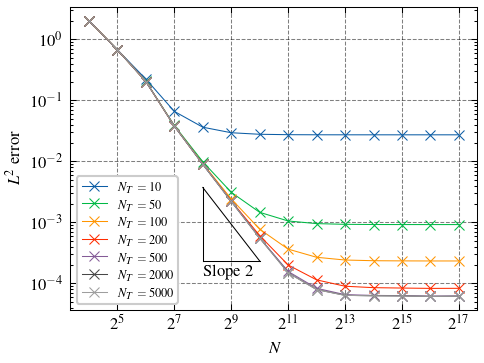

In [93]:
hs = 2*L/Ns

for j in range(len(Nts)):
    Nt = Nts[j]
    plt.plot(Ns, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = {}$".format(Nt))
#plt.plot(Ns, errors[1], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 2000$")
#plt.plot(Ns, errors[2], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 3000$")
#plt.plot(Ns, errors[3], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 4000$")
#plt.plot(Ns, errors[4], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 5000$", color="purple")
#plt.plot(h_plot, h_plot**2*np.exp(-3), label="slope-{} line".format(1), color="purple", lw=.5)

# Order lines
N_plot_2 = Ns[4:7]

s_2 = 2
order_2 = 1/N_plot_2**(s_2)*np.exp(5.5)

plt.plot(N_plot_2, order_2, color="black", lw=.5, ls="-")
plt.plot(N_plot_2, np.tile(order_2[-1], len(N_plot_2)), color="black", lw=.5, ls="-")
plt.plot(np.tile(N_plot_2[0], len(order_2)), order_2, color="black", lw=.5, ls="-")
plt.text(N_plot_2[0], order_2[-1]-1e-4, r'Slope 2')

plt.legend(fontsize=6)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N$")
plt.ylabel(r"$L^2$ error")#r"$||\psi_{num} - \psi_{theo}||_{L^2}$")
plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_N_L_40_c_0.70_k_0.25.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_N_L_40_c_0.70_k_0.25.pgf", dpi=300, bbox_inches = "tight")
#plt.grid()
plt.show()

In [95]:
EOCs = []

dic_EOC = {}
for n in range(len(Nts)):
    EOC = []
    for j in range(len(Ns)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N_T={}$".format(Nts[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Ns)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D1/EOC_tab_D1_N_L_40_c_0.70_k_0.25.txt")

       $N_T=10$  $N_T=50$  $N_T=100$  $N_T=200$  $N_T=500$  $N_T=2000$  \
16       1.5771    1.5816     1.5818     1.5818     1.5818      1.5818   
32       1.5968    1.7208     1.7247     1.7257     1.7260      1.7260   
64       1.7563    2.3943     2.4168     2.4223     2.4239      2.4242   
128      0.8607    1.9742     2.0517     2.0717     2.0773      2.0783   
256      0.3010    1.6635     1.9181     1.9939     2.0161      2.0201   
512      0.0842    1.0897     1.6500     1.8966     1.9796      1.9952   
1024     0.0217    0.4702     1.0829     1.5968     1.8364      1.8860   
2048     0.0055    0.1432     0.4433     0.8097     0.9153      0.9138   
4096     0.0014    0.0392     0.1495     0.3463     0.3463      0.3147   
8192     0.0003    0.0098     0.0373     0.0777     0.0417      0.0247   
16384    0.0001    0.0025     0.0097     0.0212     0.0116      0.0071   
32768    0.0000    0.0007     0.0041     0.0186     0.0264      0.0258   
65536    0.0000    0.0001    -0.0000  

## $L=100$ 

In [96]:
theo = pickle.load(open(path_D1 + "theo_c_0.71_k_0.25_L_100.pck", "rb"))
c = np.sqrt(2)/2
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [13]:
order = 2
tf = 5
L = 100

Ns = np.array([2**(j) for j in range(4, 18)]) #17
Nts = np.array([10, 50, 100, 200, 500, 2000, 5000])
#Nts = np.array([100, 200, 500, 2000, 5000]) 
#np.array([1000, 2000, 3000, 4000, 5000])#100, 200, 1000, 5000])
dts = tf/Nts

base = "errors_Nt_"
folders = []
errors = []
for Nt in Nts:
    folder_name = path_D1_L + base + "{N}_order_{o}/".format(N=Nt, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

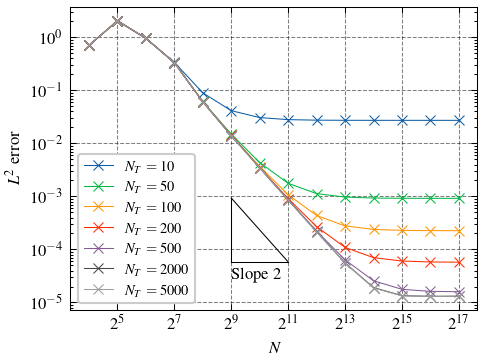

In [14]:
hs = 2*L/Ns

for j in range(len(Nts)):
    Nt = Nts[j]
    plt.plot(Ns, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = {}$".format(Nt))
#plt.plot(Ns, errors[1], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 2000$")
#plt.plot(Ns, errors[2], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 3000$")
#plt.plot(Ns, errors[3], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 4000$")
#plt.plot(Ns, errors[4], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 5000$", color="purple")
#plt.plot(h_plot, h_plot**2*np.exp(-3), label="slope-{} line".format(1), color="purple", lw=.5)

# Order lines
N_plot_2 = Ns[5:8]

s_2 = 2
order_2 = 1/N_plot_2**(s_2)*np.exp(5.5)

plt.plot(N_plot_2, order_2, color="black", lw=.5, ls="-")
plt.plot(N_plot_2, np.tile(order_2[-1], len(N_plot_2)), color="black", lw=.5, ls="-")
plt.plot(np.tile(N_plot_2[0], len(order_2)), order_2, color="black", lw=.5, ls="-")
plt.text(N_plot_2[0], order_2[-1]-3e-5, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N$")
plt.ylabel(r"$L^2$ error")

plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_N_L_100_c_0.70_k_0.25.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_N_L_100_c_0.70_k_0.25.pgf", dpi=300, bbox_inches = "tight")
#plt.grid()
plt.show()

In [17]:
EOCs = []

dic_EOC = {}
for n in range(len(Nts)):
    EOC = []
    for j in range(len(Ns)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N_T={}$".format(Nts[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Ns)[:-1]
#print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D1/EOC_tab_D1_N_L_100_c_0.70_k_0.25.txt")

# Stable dark solitons Errors in $D_2$

In [3]:
path_D2 = "../../../Heaven_scripts/Results/Errors/D2/"
path_D2_space = "../../../Heaven_scripts/Results/Errors/D2/space_order_2/"
path_D2_L = "../../../Heaven_scripts/Results/Errors/D2/space_order_2_L_200/"

## $L = 100$

In [26]:
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c = c_star + eps

In [27]:
theo = pickle.load(open(path_D2 + "theo_c_0.57_k_-50_L_100.pck", "rb"))
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [28]:
order = 2
tf = 5
L = 100

Ns = np.array([2**(j) for j in range(4, 18)])
Nts = np.array([10, 50, 100, 200, 500, 2000, 5000])
dts = tf/Nts

base = "errors_Nt_"
folders = []
errors = []
for Nt in Nts:
    folder_name = path_D2_space + base + "{N}_order_{o}/".format(N=Nt, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

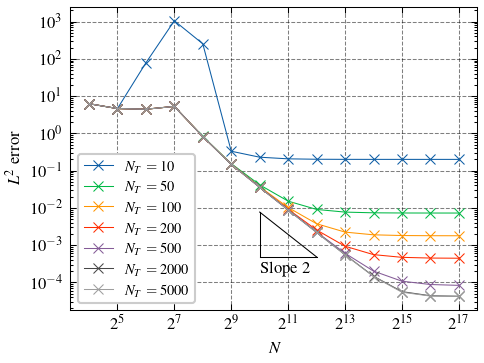

In [29]:
hs = 2*L/Ns

for j in range(len(Nts)):
    Nt = Nts[j]
    plt.plot(Ns, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = {}$".format(Nt))
#plt.plot(Ns, errors[1], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 2000$")
#plt.plot(Ns, errors[2], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 3000$")
#plt.plot(Ns, errors[3], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 4000$")
#plt.plot(Ns, errors[4], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 5000$", color="purple")
#plt.plot(h_plot, h_plot**2*np.exp(-3), label="slope-{} line".format(1), color="purple", lw=.5)

# Order lines
N_plot_2 = Ns[6:9]

s_2 = 2
order_2 = 1/N_plot_2**(s_2)*np.exp(9)

plt.plot(N_plot_2, order_2, color="black", lw=.5, ls="-")
plt.plot(N_plot_2, np.tile(order_2[-1], len(N_plot_2)), color="black", lw=.5, ls="-")
plt.plot(np.tile(N_plot_2[0], len(order_2)), order_2, color="black", lw=.5, ls="-")
plt.text(N_plot_2[0], order_2[-1]-3e-4, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N$")
plt.ylabel(r"$E^{\Delta t}_h$")#r"$||\psi_{num} - \psi_{theo}||_{L^2}$")
plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_N_L_100_k_-50_eps_0.1.pdf", dpi=600)#, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_N_L_100_k_-50_eps_0.1.pgf", dpi=600)#, bbox_inches = "tight")
#plt.grid()
plt.show()

In [30]:
EOC_1 = []
EOC_2 = []
EOC_3 = []
EOC_4 = []
EOC_5 = []

EOCs = []

dic_EOC = {}
for n in range(len(Nts)):
    EOC = []
    for j in range(len(Ns)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N_T={}$".format(Nts[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Ns)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D2/EOC_tab_D2_N_L_100_k_-50_eps_0.1.txt")

       $N_T=10$  $N_T=50$  $N_T=100$  $N_T=200$  $N_T=500$  $N_T=2000$  \
16       0.4298    0.4371     0.4374     0.4374     0.4375      0.4375   
32      -4.0772    0.0578     0.0574     0.0573     0.0573      0.0573   
64      -3.7534   -0.2503    -0.2524    -0.2530    -0.2532     -0.2532   
128      2.0554    2.6768     2.6905     2.6940     2.6950      2.6952   
256      9.5770    2.4228     2.4541     2.4617     2.4638      2.4642   
512      0.5314    1.8930     2.0177     2.0494     2.0584      2.0600   
1024     0.1461    1.4519     1.8502     1.9725     2.0079      2.0142   
2048     0.0370    0.7399     1.4490     1.8409     1.9768      2.0020   
4096     0.0093    0.2379     0.7466     1.4491     1.8925      1.9906   
8192     0.0023    0.0627     0.2415     0.7483     1.5907      1.9160   
16384    0.0006    0.0159     0.0638     0.2420     0.9000      1.3753   
32768    0.0001    0.0040     0.0161     0.0639     0.2961      0.3671   
65536    0.0000    0.0010     0.0040  

## $L = 200$

In [31]:
theo = pickle.load(open(path_D2 + "theo_c_0.57_k_-50_L_200.pck", "rb"))
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [32]:
order = 2
tf = 5
L = 200

Ns = np.array([2**(j) for j in range(4, 18)])
Nts = np.array([10, 50, 100, 200, 500, 2000, 5000])
dts = tf/Nts

base = "errors_Nt_"
folders = []
errors = []
for Nt in Nts:
    folder_name = path_D2_L + base + "{N}_order_{o}/".format(N=Nt, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

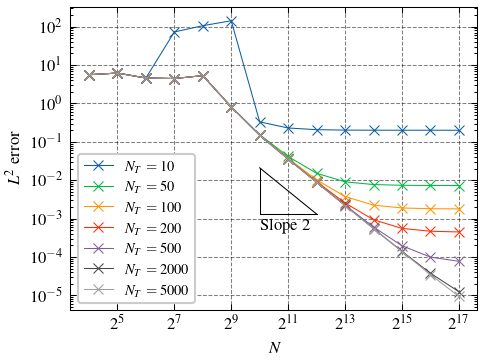

In [33]:
hs = 2*L/Ns

for j in range(len(Nts)):
    Nt = Nts[j]
    plt.plot(Ns, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = {}$".format(Nt))
#plt.plot(Ns, errors[1], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 2000$")
#plt.plot(Ns, errors[2], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 3000$")
#plt.plot(Ns, errors[3], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 4000$")
#plt.plot(Ns, errors[4], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N_T = 5000$", color="purple")
#plt.plot(h_plot, h_plot**2*np.exp(-3), label="slope-{} line".format(1), color="purple", lw=.5)

# Order lines
N_plot_2 = Ns[6:9]

s_2 = 2
order_2 = 1/N_plot_2**(s_2)*np.exp(10)

plt.plot(N_plot_2, order_2, color="black", lw=.5, ls="-")
plt.plot(N_plot_2, np.tile(order_2[-1], len(N_plot_2)), color="black", lw=.5, ls="-")
plt.plot(np.tile(N_plot_2[0], len(order_2)), order_2, color="black", lw=.5, ls="-")
plt.text(N_plot_2[0], order_2[-1]-8e-4, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N$")
plt.ylabel(r"$L^2$ error")#r"$||\psi_{num} - \psi_{theo}||_{L^2}$")
plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_N_L_200_k_-50_eps_0.1.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_N_L_200_k_-50_eps_0.1.pgf", dpi=300, bbox_inches = "tight")
#plt.grid()
plt.show()

In [35]:
EOCs = []

dic_EOC = {}
for n in range(len(Nts)):
    EOC = []
    for j in range(len(Ns)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]

    dic_EOC["$N_T={}$".format(Nts[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Ns)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D2/EOC_tab_D2_N_L_200_k_-50_eps_0.1.txt")

       $N_T=10$  $N_T=50$  $N_T=100$  $N_T=200$  $N_T=500$  $N_T=2000$  \
16      -0.1356   -0.1424    -0.1426    -0.1426    -0.1426     -0.1426   
32       0.4209    0.4298     0.4302     0.4303     0.4303      0.4303   
64      -3.9863    0.0444     0.0441     0.0440     0.0440      0.0440   
128     -0.5428   -0.2490    -0.2510    -0.2518    -0.2521     -0.2522   
256     -0.4256    2.6916     2.7049     2.7085     2.7096      2.7097   
512      8.7474    2.4115     2.4430     2.4508     2.4530      2.4534   
1024     0.5303    1.8914     2.0160     2.0480     2.0569      2.0585   
2048     0.1459    1.4511     1.8495     1.9717     2.0071      2.0134   
4096     0.0370    0.7396     1.4486     1.8407     1.9767      2.0019   
8192     0.0093    0.2378     0.7466     1.4501     1.8954      1.9942   
16384    0.0023    0.0627     0.2416     0.7508     1.6189      1.9730   
32768    0.0006    0.0159     0.0638     0.2436     0.9861      1.8917   
65536    0.0001    0.0040     0.0161  